In [1]:
### Imports and Libraries

import os
import pickle
import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from shapely.geometry import box
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel, RationalQuadratic
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import KFold

# Import sorted data for section of choice
section_name = "Lower"
complete_data = pd.read_csv(f"sorted_data/complete_data_{section_name}.csv")
complete_data_crs = "ESRI:102690"

# Drop rows without coordinates. Do NOT reuse the Middle-only Northing < 321000
# cutoff here: that filter is for Middle's northern transect and would wipe
# Upper (northings ~362k-370k) or be meaningless for Lower (~216k-252k).
complete_data = complete_data.dropna(subset=["Northing", "Easting"]).copy()
print(f"Loaded {len(complete_data)} points for section '{section_name}'")
if complete_data.empty:
    raise ValueError(f"No points loaded for section '{section_name}'. Check sorted_data/complete_data_{section_name}.csv")


FileNotFoundError: [Errno 2] No such file or directory: 'sorted_data/complete_data_Lower.csv'

Original centerline CRS: EPSG:4269
Original Lower Data CRS: PROJCS["NAD_1983_StatePlane_Michigan_South_FIPS_2113_Feet",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4269"]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",41.5],PARAMETER["central_meridian",-84.3666666666667],PARAMETER["standard_parallel_1",42.1],PARAMETER["standard_parallel_2",43.6666666666667],PARAMETER["false_easting",13123333.3333333],PARAMETER["false_northing",0],UNIT["US survey foot",0.304800609601219,AUTHORITY["EPSG","9003"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["ESRI","102690"]]
Converted centerline CRS: PROJCS["NAD_1983_StatePlane_Michigan_South_FIPS_2113_Feet",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUT

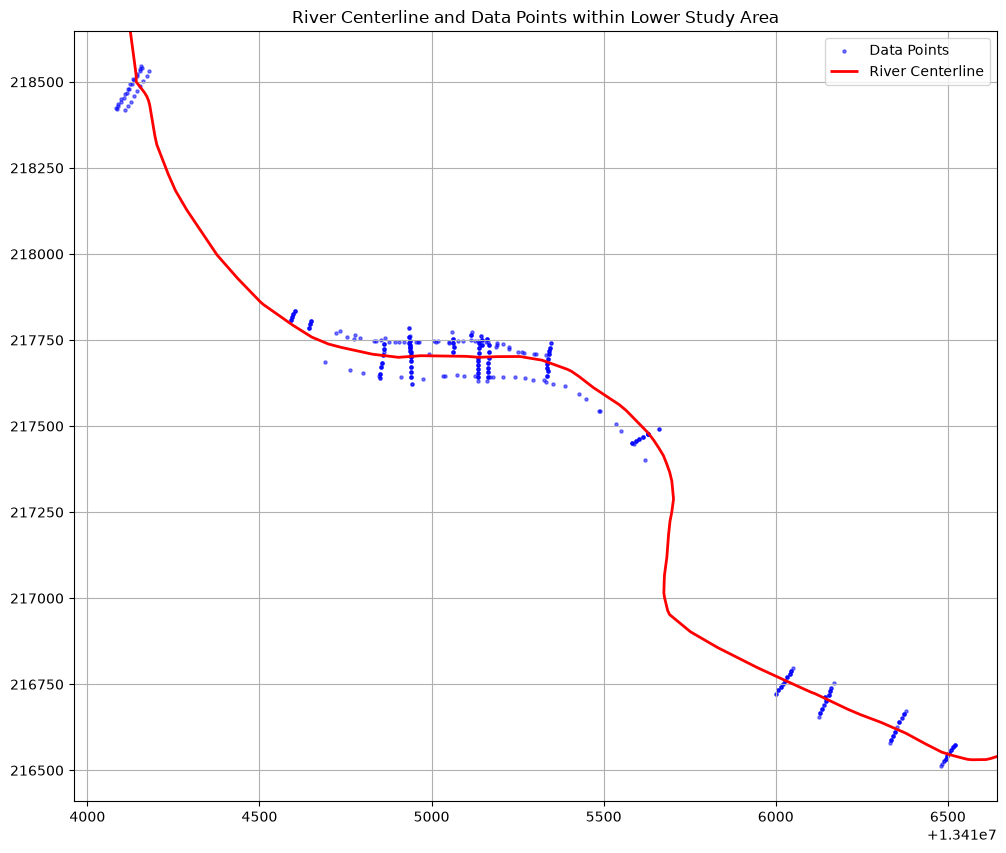

In [ ]:
### 5) Centerline Import and Trimming

# Import centerline GeoJSON
centerline = gpd.read_file("mapping/Huron_RiverSystem.geojson")
print(f"Original centerline CRS: {centerline.crs}")

# Import section data GeoJSON (CRS source for the centerline)
df_section = gpd.read_file(f"mapping/data_{section_name}.geojson")
print(f"Original {section_name} Data CRS: {df_section.crs}")

# Convert centerline CRS to match complete_data CRS
centerline = centerline.to_crs(df_section.crs)
print(f"Converted centerline CRS: {centerline.crs}")

### Trim the Massive Centerline File to Match Data Size
# Get the min/max bounds of Easting (X) and Northing (Y) columns
x_min = complete_data["Easting"].min()
x_max = complete_data["Easting"].max()
y_min = complete_data["Northing"].min()
y_max = complete_data["Northing"].max()

print("\nData bounds:")
print(f"X: {x_min:.1f} to {x_max:.1f}")
print(f"Y: {y_min:.1f} to {y_max:.1f}")

# Create a bounding box polygon using (minx, miny, maxx, maxy)
bbox = box(x_min, y_min, x_max, y_max)

# Clip centerline to data bounds
centerline_clipped = centerline[centerline.geometry.intersects(bbox)]

print(f"\nCenterline features reduced from {len(centerline)} to {len(centerline_clipped)}")

# Update centerline variable to use clipped version
centerline = centerline_clipped

### Visualize the Centerline and Data Overlapped
# Create a bounding box for visualization
bbox_gdf = gpd.GeoDataFrame(geometry=[bbox], crs=complete_data_crs)

# Create figure and axis
fig, ax = plt.subplots(figsize=(15, 10))

# Plot the trimmed data points (same rows as dataSorting GeoJSON / later GP cells)
scatter = ax.scatter(complete_data["Easting"], complete_data["Northing"], color='blue', alpha=0.5, s=5, label='Data Points')

# Plot the centerline
centerline.plot(ax=ax, color='red', linewidth=2, label='River Centerline')

# Set the plot bounds to match the bbox bounds with small buffer
bbox_minx, bbox_miny, bbox_maxx, bbox_maxy = bbox.bounds
x_buffer = (bbox_maxx - bbox_minx) * 0.05  # 5% buffer
y_buffer = (bbox_maxy - bbox_miny) * 0.05  # 5% buffer
ax.set_xlim(bbox_minx - x_buffer, bbox_maxx + x_buffer)
ax.set_ylim(bbox_miny - y_buffer, bbox_maxy + y_buffer)

# Add title and legend
plt.title(f'River Centerline and Data Points within {section_name} Study Area')
plt.legend()

# Add gridlines
ax.grid(True)

# Show the plot
plt.show()


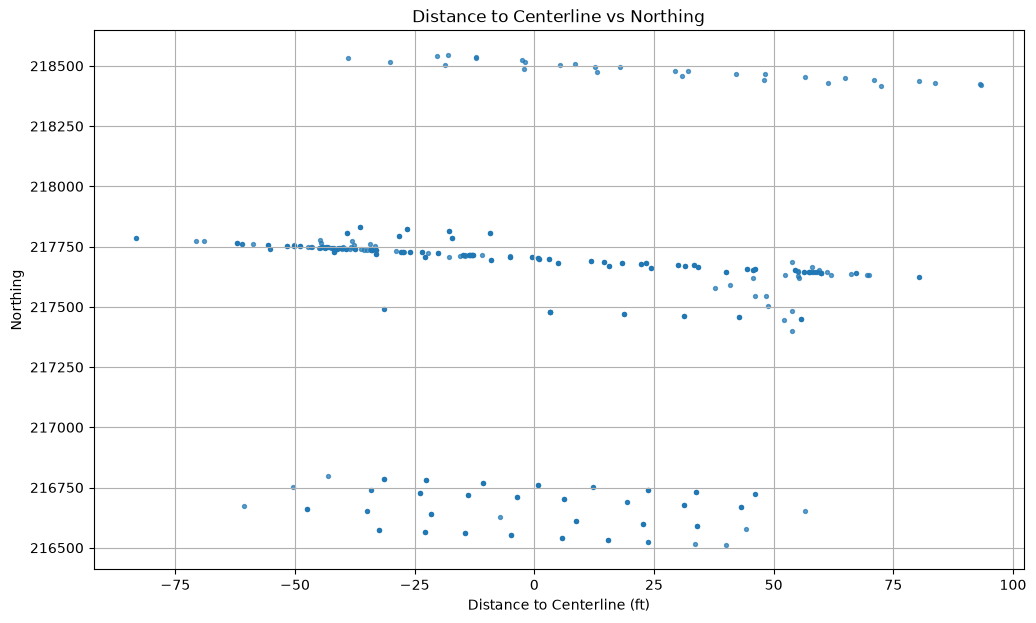

In [ ]:
### 5+6) Load Precomputed Distance to Centerline
# Distances are computed once in dataSorting.ipynb (section 6) from mapping/data_{Section}.geojson
# against the river centerline, and stored in sorted_data/data_{Section}_trimmed.csv.
# That trimmed CSV contains exactly the rows that survive the depth/velocity filters above,
# so we can use it directly instead of re-running the ~8 minute distance calculation here.

### Plot the results to debug
plt.figure(figsize=(12, 7))
plt.scatter(complete_data['distance_to_centerline'], complete_data['Northing'], s=8, alpha=0.7)
plt.xlabel("Distance to Centerline (ft)")
plt.ylabel("Northing")
plt.title("Distance to Centerline vs Northing")
plt.grid(True)
plt.show()

Reference Distance for Calc = 99494.05 feet

Downstream distances loaded for 404 points
Distance range: 0.0 to 3498.9 feet
All distances are non-negative (as expected)


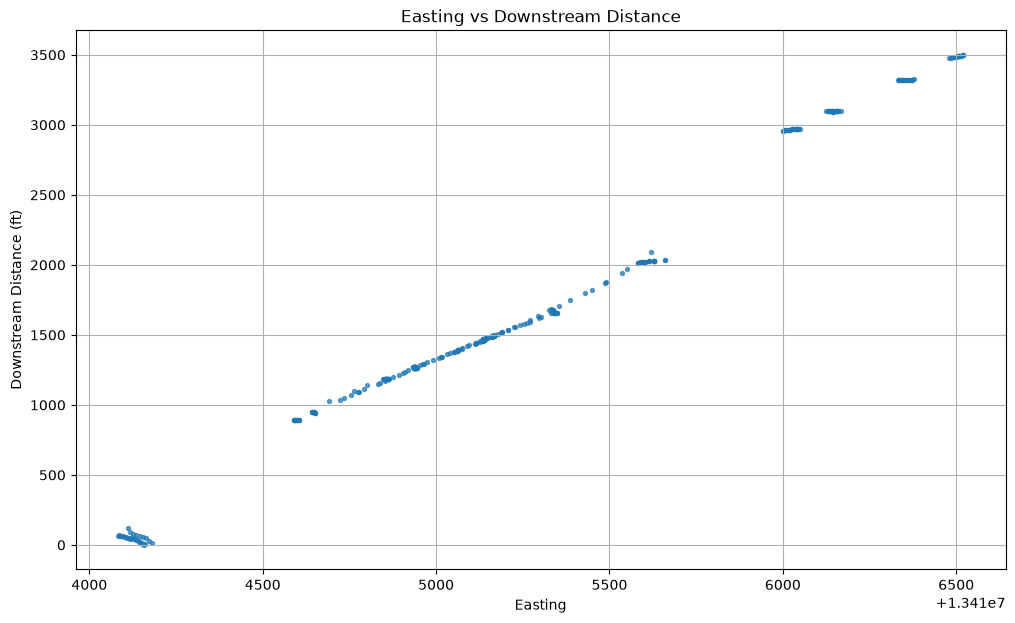

In [ ]:
### 7) Downstream Distance (precomputed in dataSorting.ipynb)
# downstream_dist is computed in dataSorting.ipynb section 6 by projecting each point onto the
# section's merged main-stem centerline (line.project) and subtracting the reference distance
# (the upstream-most projected point among points within 150 ft of the centerline).
# The column is already present in complete_data, loaded from data_{Section}_trimmed.csv above.
#
# NOTE: for translating model results back to coordinates, rebuild the SAME main-stem
# centerline as dataSorting (section bbox + 500 ft buffer + build_main_stem). The absolute
# projected distance is stored in 'dist_along_centerline', so the reference is recoverable
# directly from the data (it is the same constant for every row):
reference_distance = (complete_data['dist_along_centerline'] - complete_data['downstream_dist']).iloc[0]
# MAKE SURE THIS IS THE SAME REFERENCE POINT WHICH IS USED LATER FOR TRANSLATION OF MODEL BACK TO LAT LONG!

print(f"Reference Distance for Calc = {reference_distance:.2f} feet")

valid_downstream = complete_data['downstream_dist'].dropna()
print(f"\nDownstream distances loaded for {valid_downstream.size} points")
print(f"Distance range: {valid_downstream.min():.1f} to {valid_downstream.max():.1f} feet")

# Verify no negative distances (the 150 ft filter above removed any point upstream of the reference)
negative_count = (valid_downstream < -0.01).sum()  # Allow small floating point errors
if negative_count > 0:
    print(f"WARNING: {negative_count} points have negative distances (should be 0)")
else:
    print("All distances are non-negative (as expected)")

### Plot the results to debug
plt.figure(figsize=(12, 7))
plt.scatter(complete_data['Easting'], complete_data['downstream_dist'], s=8, alpha=0.7)
plt.xlabel("Easting")
plt.ylabel("Downstream Distance (ft)")
plt.title("Easting vs Downstream Distance")
plt.grid(True)
plt.show()


In [ ]:
### 8) 3 Input GP
# Takes about 2 mins to run
# Details: 
# 3-Variable Gaussian Process Regression Model (SI UNITS)
# Inputs: upstream_depth (m), downstream_dist (m), distance_to_centerline (m)
# Output: Velocity (m/s)
# Kernel: RBF + RationalQuadratic
# *Data converted from Imperial (ft, ft/s) to SI (m, m/s)
FT_TO_M = 0.3048

print("="*80)
print("3-VARIABLE GAUSSIAN PROCESS REGRESSION MODEL (SI UNITS)")
print("="*80)

# Define input and output columns - CHANGE THESE AS NEEDED
input_columns_3v = ['upstream_depth', 'downstream_dist', 'distance_to_centerline']
output_column_3v = 'Velocity'

print(f"\nModel Configuration:")
print(f"  Input Variables: {', '.join(input_columns_3v)}")
print(f"  Output Variable: {output_column_3v}")
print(f"  Kernel Type: RBF + RationalQuadratic")
print(f"  Units: SI (meters, m/s)")
print(f"  Conversion Factor: 1 ft = {FT_TO_M} m")

# Filter data to only include rows with non-null values for all required columns
gp_data_3v = complete_data[
    complete_data[input_columns_3v[0]].notna() & 
    complete_data[input_columns_3v[1]].notna() & 
    complete_data[input_columns_3v[2]].notna() &
    complete_data[output_column_3v].notna()
].copy()

print(f"\nData Summary:")
print(f"  Total points in streambed dataset: {len(complete_data)}")
print(f"  Points with all required data: {len(gp_data_3v)}")
print(f"  Data coverage: {len(gp_data_3v)/len(complete_data)*100:.1f}%")

# Define units for each column (SI units)
column_units_3v = {
    'Velocity': 'm/s',
    'upstream_depth': 'm',
    'downstream_dist': 'm',
    'distance_to_centerline': 'm',
    'Depth': 'm'
}

# Create readable labels from column names
def format_label_3v(col_name):
    """Convert column name to readable label"""
    return col_name.replace('_', ' ').title()

# Get units for current columns
input_unit_1_3v = column_units_3v.get(input_columns_3v[0], '')
input_unit_2_3v = column_units_3v.get(input_columns_3v[1], '')
input_unit_3_3v = column_units_3v.get(input_columns_3v[2], '')
output_unit_3v = column_units_3v.get(output_column_3v, '')

# Create labels with units
input_label_1_3v = f"{format_label_3v(input_columns_3v[0])} ({input_unit_1_3v})" if input_unit_1_3v else format_label_3v(input_columns_3v[0])
input_label_2_3v = f"{format_label_3v(input_columns_3v[1])} ({input_unit_2_3v})" if input_unit_2_3v else format_label_3v(input_columns_3v[1])
input_label_3_3v = f"{format_label_3v(input_columns_3v[2])} ({input_unit_3_3v})" if input_unit_3_3v else format_label_3v(input_columns_3v[2])
output_label_3v = f"{format_label_3v(output_column_3v)} ({output_unit_3v})" if output_unit_3v else format_label_3v(output_column_3v)

# ===== CONVERT FROM IMPERIAL TO SI UNITS =====
print(f"\nConverting units from Imperial to SI...")
print(f"  Original data in: ft, ft/s")
print(f"  Converted to: m, m/s")

# Convert the DataFrame columns FIRST (so everything downstream uses SI)
for col in input_columns_3v:
    gp_data_3v[col] = gp_data_3v[col] * FT_TO_M
gp_data_3v[output_column_3v] = gp_data_3v[output_column_3v] * FT_TO_M

# Prepare input features (X) and target variable (y) - already in SI now
X_3v = gp_data_3v[input_columns_3v].values        # ← now extracts SI units
y_3v = gp_data_3v[output_column_3v].values        # ← now in m/s
print(f"DataFrame converted to SI units")

print(f"\nFeature shapes:")
print(f"  X (inputs): {X_3v.shape}")
print(f"  y (target): {y_3v.shape}")

print(f"\nFeature statistics:")
print(f"  {input_label_1_3v} range: [{X_3v[:, 0].min():.3f}, {X_3v[:, 0].max():.3f}]")
print(f"  {input_label_2_3v} range: [{X_3v[:, 1].min():.3f}, {X_3v[:, 1].max():.3f}]")
print(f"  {input_label_3_3v} range: [{X_3v[:, 2].min():.3f}, {X_3v[:, 2].max():.3f}]")
print(f"  {output_label_3v} range: [{y_3v.min():.3f}, {y_3v.max():.3f}]")

####### Define the GP kernel - RBF + RationalQuadratic ############# KERNEL ################
kernel_3v = C(1.0, (0.1, 10.0)) * (RBF([5.0, 5.0, 5.0], (0.1, 100.0)) + RationalQuadratic(length_scale=5.0, alpha=1.0, length_scale_bounds=(0.1, 100.0), alpha_bounds=(0.1, 10.0))) + WhiteKernel(0.1, (1e-3, 1.0))

## K-FOLD CROSS-VALIDATION
print("\n" + "-"*80)
print("Performing 5-Fold Cross-Validation...")
print("-"*80)

n_folds = 5
kfold = KFold(n_splits=n_folds, shuffle=True, random_state=42)

cv_r2_scores = []
cv_rmse_scores = []
cv_mae_scores = []

for fold_idx, (train_idx, val_idx) in enumerate(kfold.split(X_3v)):
    # Split data for this fold
    X_train_cv, X_val_cv = X_3v[train_idx], X_3v[val_idx]
    y_train_cv, y_val_cv = y_3v[train_idx], y_3v[val_idx]
    
    # Scale on training fold only (prevents data leakage)
    scaler_X_cv = StandardScaler()
    scaler_y_cv = StandardScaler()
    
    X_train_scaled_cv = scaler_X_cv.fit_transform(X_train_cv)
    y_train_scaled_cv = scaler_y_cv.fit_transform(y_train_cv.reshape(-1, 1)).ravel()
    X_val_scaled_cv = scaler_X_cv.transform(X_val_cv)
    
    # Train GP on this fold
    gp_cv = GaussianProcessRegressor(
        kernel=kernel_3v,
        n_restarts_optimizer=15,
        alpha=1e-6,
        normalize_y=False,
        random_state=42
    )
    gp_cv.fit(X_train_scaled_cv, y_train_scaled_cv)
    
    # Predict on validation fold
    y_val_pred_scaled = gp_cv.predict(X_val_scaled_cv)
    y_val_pred = scaler_y_cv.inverse_transform(y_val_pred_scaled.reshape(-1, 1)).ravel()
    
    # Calculate fold metrics
    fold_r2 = r2_score(y_val_cv, y_val_pred)
    fold_rmse = np.sqrt(mean_squared_error(y_val_cv, y_val_pred))
    fold_mae = mean_absolute_error(y_val_cv, y_val_pred)
    
    cv_r2_scores.append(fold_r2)
    cv_rmse_scores.append(fold_rmse)
    cv_mae_scores.append(fold_mae)
    
    print(f"  Fold {fold_idx + 1}: R2 = {fold_r2:.4f}, RMSE = {fold_rmse:.4f}, MAE = {fold_mae:.4f}")

# Store CV metrics for use in visualizations (these are the TRUE generalization metrics)
cv_r2_mean = np.mean(cv_r2_scores)
cv_r2_std = np.std(cv_r2_scores)
cv_rmse_mean = np.mean(cv_rmse_scores)
cv_rmse_std = np.std(cv_rmse_scores)
cv_mae_mean = np.mean(cv_mae_scores)
cv_mae_std = np.std(cv_mae_scores)

print("\n" + "="*80)
print("CROSS-VALIDATION RESULTS (True Generalization Performance)")
print("="*80)
print(f"  R2 Score:  {cv_r2_mean:.4f} +/- {cv_r2_std:.4f}")
print(f"  RMSE:      {cv_rmse_mean:.4f} +/- {cv_rmse_std:.4f}")
print(f"  MAE:       {cv_mae_mean:.4f} +/- {cv_mae_std:.4f}")

# FINAL MODEL TRAINING (on all data)
print("\n" + "-"*80)
print("Training Final Model on All Data (for predictions)...")
print("-"*80)

# Standardize features using ALL data for final model
scaler_X_3v = StandardScaler()
scaler_y_3v = StandardScaler()

X_scaled_3v = scaler_X_3v.fit_transform(X_3v)
y_scaled_3v = scaler_y_3v.fit_transform(y_3v.reshape(-1, 1)).ravel()

# Create and train the final GP model on all data
gp_model_3v = GaussianProcessRegressor(
    kernel=kernel_3v,
    n_restarts_optimizer=15,
    alpha=1e-6,
    normalize_y=False,
    random_state=42
)

# Fit the model
gp_model_3v.fit(X_scaled_3v, y_scaled_3v)

print(f"Final model trained successfully!")
print(f"\nOptimized kernel: {gp_model_3v.kernel_}")

# Make predictions on the training data (for residual analysis and plotting only)
y_pred_scaled_3v, y_std_scaled_3v = gp_model_3v.predict(X_scaled_3v, return_std=True)

# Transform predictions back to original scale
y_pred_3v = scaler_y_3v.inverse_transform(y_pred_scaled_3v.reshape(-1, 1)).ravel()
y_std_3v = y_std_scaled_3v * scaler_y_3v.scale_

# Calculate training metrics (reference values, true are the cross validation results)
r2_3v = r2_score(y_3v, y_pred_3v)
rmse_3v = np.sqrt(mean_squared_error(y_3v, y_pred_3v))
mae_3v = mean_absolute_error(y_3v, y_pred_3v)

print("\n" + "="*80)
print("TRAINING SET METRICS (for reference - may need spatial or time CV)")
print("="*80)
print(f"  R2 Score: {r2_3v:.4f}")
print(f"  RMSE: {rmse_3v:.4f}")
print(f"  MAE: {mae_3v:.4f}")
print(f"  Mean prediction uncertainty: {y_std_3v.mean():.4f}")
print("\n  NOTE: Use Cross-Validation metrics above for true generalization performance!")

# Add predictions to the dataframe
gp_data_3v[f'{output_column_3v}_predicted'] = y_pred_3v
gp_data_3v[f'{output_column_3v}_uncertainty'] = y_std_3v

# Calculate residuals
gp_data_3v['residual'] = gp_data_3v[output_column_3v] - gp_data_3v[f'{output_column_3v}_predicted']

print(f"\nResidual statistics:")
print(f"  Mean residual: {gp_data_3v['residual'].mean():.4f}")
print(f"  Std residual: {gp_data_3v['residual'].std():.4f}")
print(f"  Min residual: {gp_data_3v['residual'].min():.4f}")
print(f"  Max residual: {gp_data_3v['residual'].max():.4f}")


3-VARIABLE GAUSSIAN PROCESS REGRESSION MODEL (SI UNITS)

Model Configuration:
  Input Variables: upstream_depth, downstream_dist, distance_to_centerline
  Output Variable: Velocity
  Kernel Type: RBF + RationalQuadratic
  Units: SI (meters, m/s)
  Conversion Factor: 1 ft = 0.3048 m

Data Summary:
  Total points in streambed dataset: 404
  Points with all required data: 404
  Data coverage: 100.0%

Converting units from Imperial to SI...
  Original data in: ft, ft/s
  Converted to: m, m/s
DataFrame converted to SI units

Feature shapes:
  X (inputs): (404, 3)
  y (target): (404,)

Feature statistics:
  Upstream Depth (m) range: [0.282, 0.706]
  Downstream Dist (m) range: [0.000, 1066.467]
  Distance To Centerline (m) range: [-25.371, 28.466]
  Velocity (m/s) range: [0.000, 1.579]

--------------------------------------------------------------------------------
Performing 5-Fold Cross-Validation...
--------------------------------------------------------------------------------
  Fold 1:

In [ ]:
### 9) Pickle the trained GP model and outputs

pickle_path = f"model outputs/gp_model_{section_name}.pkl"

gp_output = {
    "section_name": section_name,
    "gp_model_3v": gp_model_3v,
    "scaler_X_3v": scaler_X_3v,
    "scaler_y_3v": scaler_y_3v,
    "X_3v": X_3v,
    "y_3v": y_3v,
    "y_pred_3v": y_pred_3v,
    "y_std_3v": y_std_3v,
    "gp_data_3v": gp_data_3v,
    "input_columns_3v": input_columns_3v,
    "output_column_3v": output_column_3v,
    "output_unit_3v": output_unit_3v,
    "input_label_1_3v": input_label_1_3v,
    "input_label_2_3v": input_label_2_3v,
    "input_label_3_3v": input_label_3_3v,
    "output_label_3v": output_label_3v,
    "r2_3v": r2_3v,
    "rmse_3v": rmse_3v,
    "mae_3v": mae_3v,
    "cv_r2_mean": cv_r2_mean,
    "cv_r2_std": cv_r2_std,
    "cv_rmse_mean": cv_rmse_mean,
    "cv_rmse_std": cv_rmse_std,
    "cv_mae_mean": cv_mae_mean,
    "cv_mae_std": cv_mae_std,
    "kernel": str(gp_model_3v.kernel_),
    "FT_TO_M": FT_TO_M,
    "reference_distance": reference_distance
}

with open(pickle_path, "wb") as f:
    pickle.dump(gp_output, f, protocol=pickle.HIGHEST_PROTOCOL)

print(f"Saved GP model outputs to {pickle_path}")
print("Reload later with:")
print("    with open(pickle_path, 'rb') as f:")
print("        gp_output = pickle.load(f)")
print("    gp_model_3v = gp_output['gp_model_3v']")
print("    scaler_X_3v = gp_output['scaler_X_3v']")
print("    scaler_y_3v = gp_output['scaler_y_3v']")


Saved GP model outputs to model outputs/gp_model_Lower.pkl
Reload later with:
    with open(pickle_path, 'rb') as f:
        gp_output = pickle.load(f)
    gp_model_3v = gp_output['gp_model_3v']
    scaler_X_3v = gp_output['scaler_X_3v']
    scaler_y_3v = gp_output['scaler_y_3v']
